In [1]:
import torch
import torch.nn as nn
import yfinance as yf
from tqdm import tqdm

In [2]:
# hyperparameters
train_test_prop = 0.8
batch_size = 16 # how many independent sequences will we process in parallel?
block_size = 8 # the temporal block size of the model
max_iters = 100
learning_rate = 3e-4
scheduler_step_size = 40
scheduler_gamma = 0.5
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200

# model parameters
n_hidden = 128
n_layer = 2
dropout = 0.2
is_lstm = True

torch.manual_seed(1337)

In [3]:
data = yf.download("AMZN")
data.columns = data.columns.droplevel(1)
data = data["2020-01-01":]


[*********************100%***********************]  1 of 1 completed


In [4]:
data["1D Return"] = data["Close"].pct_change(1)
data["5D Return"] = data["Close"].pct_change(5)
data["20D Return"] = data["Close"].pct_change(20)
data["80D Return"] = data["Close"].pct_change(80)
data["120D Return"] = data["Close"].pct_change(120)
data["160D Return"] = data["Close"].pct_change(160)
data["200D Return"] = data["Close"].pct_change(200)
data["20D EMA"] = data["Close"].ewm(span=20, adjust=False).mean()
data["80D EMA"] = data["Close"].ewm(span=80, adjust=False).mean()
data["120D EMA"] = data["Close"].ewm(span=120, adjust=False).mean()
data["160D EMA"] = data["Close"].ewm(span=160, adjust=False).mean()
data["200D EMA"] = data["Close"].ewm(span=200, adjust=False).mean()
data.dropna(inplace=True)
data

Price,Adj Close,Close,High,Low,Open,Volume,1D Return,5D Return,20D Return,80D Return,120D Return,160D Return,200D Return,20D EMA,80D EMA,120D EMA,160D EMA,200D EMA
Date,,,,,,,,,,,,,,,,,,
2020-10-16,163.635498,163.635498,169.983002,158.000000,168.161499,129488000,-0.019750,-0.004241,0.107550,0.196866,0.414260,0.674920,0.724285,162.155254,153.740987,146.638413,140.434857,135.321374
2020-10-19,160.360504,160.360504,166.449997,159.636993,164.980499,104472000,-0.020014,-0.068465,0.083345,0.164319,0.351708,0.680056,0.710539,161.984326,153.904432,146.865224,140.682381,135.570519
2020-10-20,160.850494,160.850494,163.300003,159.600494,161.113998,90194000,0.003056,-0.065809,0.028130,0.194640,0.300327,0.628182,0.690601,161.876342,154.075940,147.096386,140.932917,135.822061
2020-10-21,159.246994,159.246994,161.694000,158.000000,160.625000,91854000,-0.009969,-0.053147,0.061696,0.188242,0.393213,0.655348,0.670254,161.625928,154.203620,147.297222,141.160421,136.055145
2020-10-22,158.820007,158.820007,159.937500,156.097000,159.493500,84240000,-0.002681,-0.048597,0.051861,0.151362,0.371509,0.670831,0.678885,161.358697,154.317605,147.487681,141.379794,136.281661
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-18,220.520004,220.520004,231.399994,220.110001,230.770004,43281400,-0.045987,-0.042300,0.077758,0.256524,0.141113,0.231955,0.266483,219.219800,201.137222,195.400003,190.702435,186.397904
2024-12-19,223.289993,223.289993,226.089996,222.919998,224.910004,39918700,0.012561,-0.024807,0.100601,0.289799,0.132302,0.208802,0.286900,219.607438,201.684204,195.860995,191.107250,186.764990
2024-12-20,224.919998,224.919998,226.210007,218.729996,219.839996,88279200,0.007300,-0.011167,0.133784,0.316862,0.124600,0.207884,0.272028,220.113396,202.257927,196.341309,191.527284,187.144642


In [5]:
data.drop(columns=["Close", "Adj Close", "Open", "High", "Low", "Volume"], inplace=True)
data

Price,1D Return,5D Return,20D Return,80D Return,120D Return,160D Return,200D Return,20D EMA,80D EMA,120D EMA,160D EMA,200D EMA
Date,,,,,,,,,,,,
2020-10-16,-0.019750,-0.004241,0.107550,0.196866,0.414260,0.674920,0.724285,162.155254,153.740987,146.638413,140.434857,135.321374
2020-10-19,-0.020014,-0.068465,0.083345,0.164319,0.351708,0.680056,0.710539,161.984326,153.904432,146.865224,140.682381,135.570519
2020-10-20,0.003056,-0.065809,0.028130,0.194640,0.300327,0.628182,0.690601,161.876342,154.075940,147.096386,140.932917,135.822061
2020-10-21,-0.009969,-0.053147,0.061696,0.188242,0.393213,0.655348,0.670254,161.625928,154.203620,147.297222,141.160421,136.055145
2020-10-22,-0.002681,-0.048597,0.051861,0.151362,0.371509,0.670831,0.678885,161.358697,154.317605,147.487681,141.379794,136.281661
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-18,-0.045987,-0.042300,0.077758,0.256524,0.141113,0.231955,0.266483,219.219800,201.137222,195.400003,190.702435,186.397904
2024-12-19,0.012561,-0.024807,0.100601,0.289799,0.132302,0.208802,0.286900,219.607438,201.684204,195.860995,191.107250,186.764990
2024-12-20,0.007300,-0.011167,0.133784,0.316862,0.124600,0.207884,0.272028,220.113396,202.257927,196.341309,191.527284,187.144642


In [6]:
split_index = int(data.shape[0] * train_test_prop)
train_x = data.iloc[:split_index]
test_x = data.iloc[split_index:]
train_y = (train_x["1D Return"].shift(-1).dropna() > 0).astype("int16")
test_y = (test_x["1D Return"].shift(-1).dropna() > 0).astype("int16")
train_x = train_x.loc[train_y.index]
test_x = test_x.loc[test_y.index]
assert train_x.index.equals(train_y.index)
assert test_x.index.equals(test_y.index)
train_x.shape, train_y.shape, test_x.shape, test_y.shape

((842, 12), (842,), (210, 12), (210,))

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(train_x)
train_x = scaler.transform(train_x)
test_x = scaler.transform(test_x)

In [8]:
from torch.utils.data import DataLoader, Dataset

class TimeSeriesDataset(Dataset):
    def __init__(self, x, y, block_size):
        self.x = x
        self.y = y
        self.block_size = block_size

    def __len__(self):
        return self.x.shape[0] - self.block_size

    def __getitem__(self, idx):
        return (
            torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
            torch.tensor(self.y[idx], dtype=torch.bool)
        )


In [9]:
train_x = torch.tensor(train_x, dtype=torch.float32).to(device)
train_y = torch.tensor(train_y.values, dtype=torch.float32).to(device) 

train_dataset = TimeSeriesDataset(train_x, train_y, block_size)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_x = torch.tensor(test_x, dtype=torch.float32).to(device)
test_y = torch.tensor(test_y.values, dtype=torch.float32).to(device)

test_dataset = TimeSeriesDataset(test_x, test_y, block_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [10]:
for i, j in train_loader:
    print(i.shape, j.shape)


torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 8, 12]) torch.Size([16])
torch.Size([16, 

C:\Users\luis\AppData\Local\Temp\ipykernel_31492\2273534199.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_31492\2273534199.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.bool)


In [11]:
class LSTMModel(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_layers: int, output_size: int, dropout: float):
        super(LSTMModel, self).__init__()
        # self.net = nn.Sequential(
        #     nn.Linear(input_size, hidden_size),
        #     nn.ReLU(),
        #     nn.LSTM(hidden_size, hidden_size, num_layers, batch_first=True, dropout=dropout),
        #     nn.Linear(hidden_size, output_size)
        # )
        self.linear = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        if is_lstm:
            self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.output = nn.Linear(hidden_size, output_size)
        self.sigmoid = nn.Sigmoid()
        # self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LSTM):
            for name, param in module.named_parameters():
                if 'bias' in name:
                    nn.init.constant_(param, 0.0)
                elif 'weight_ih' in name:
                    nn.init.kaiming_normal_(param)
                elif 'weight_hh' in name:
                    nn.init.orthogonal_(param)
    
    def forward(self, idx):
        # idx: (batch_size, block_size, input_size) i.e. B x T x C
        x = self.linear(idx)
        x = self.relu(x)
        if is_lstm:
            x, _ = self.lstm(x)
            x = x[:, -1, :]
        x = self.output(x)
        print(self.sigmoid(x))
        return self.sigmoid(x)
    

In [12]:
def run_epoch(model, criterion, optimizer, scheduler, dataloader, is_training=False):
    epoch_loss = 0
    
    if is_training:
        model.train()
    else:
        model.eval()
    for idx, (x, y) in enumerate(dataloader):
        if is_training:
            optimizer.zero_grad()

        batchsize = x.shape[0]


        x = x.to(device)
        y = y.to(device)
                
        out = model(x)
        print(out.contiguous(), y.shape)
        loss = criterion(out.contiguous(), y)

        if is_training:
            loss.backward()
            optimizer.step()

        epoch_loss += (loss.detach().item() / batchsize)

    lr = scheduler.get_last_lr()[0]

    return epoch_loss, lr


In [13]:
# test_model = LSTMModel(input_size=train_x.shape[1], hidden_size=n_hidden, num_layers=n_layer, output_size=1, dropout=dropout).to(device)
# test_criterion = nn.MSELoss()
# test_optimizer = torch.optim.Adam(test_model.parameters(), lr=learning_rate)
# test_scheduler = torch.optim.lr_scheduler.StepLR(test_optimizer, step_size=scheduler_step_size, gamma=scheduler_gamma)

# run_epoch(test_model, test_criterion, test_optimizer, test_scheduler, train_loader, is_training=False)


In [14]:
model = LSTMModel(input_size=train_x.shape[1], hidden_size=n_hidden, num_layers=n_layer, output_size=1, dropout=0.2).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=scheduler_step_size, gamma=scheduler_gamma)


for epoch in tqdm(range(max_iters)):
    loss_train, lr_train = run_epoch(model, criterion, optimizer, scheduler, train_loader, is_training=True)
    loss_val, lr_val = run_epoch(model, criterion, optimizer, scheduler, test_loader, is_training=False)
    scheduler.step()

    print('Epoch[{}/{}] | loss train:{:.6f}, test:{:.6f} | lr:{:.6f}'
          .format(epoch + 1, max_iters, loss_train, loss_val, lr_train))


  0%|          | 0/100 [00:00<?, ?it/s]C:\Users\luis\AppData\Local\Temp\ipykernel_31492\2273534199.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_31492\2273534199.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.bool)
  0%|          | 0/100 [00:00<?, ?it/s]

tensor([[0.4776],
        [0.4811],
        [0.4802],
        [0.4841],
        [0.4776],
        [0.4750],
        [0.4855],
        [0.4840],
        [0.4722],
        [0.4751],
        [0.4780],
        [0.4765],
        [0.4784],
        [0.4883],
        [0.4806],
        [0.4809]], device='cuda:0', grad_fn=<SigmoidBackward0>)
tensor([[0.4776],
        [0.4811],
        [0.4802],
        [0.4841],
        [0.4776],
        [0.4750],
        [0.4855],
        [0.4840],
        [0.4722],
        [0.4751],
        [0.4780],
        [0.4765],
        [0.4784],
        [0.4883],
        [0.4806],
        [0.4809]], device='cuda:0', grad_fn=<SigmoidBackward0>) torch.Size([16])


RuntimeError: "nll_loss_forward_reduce_cuda_kernel_2d_index" not implemented for 'Bool'

In [15]:
import numpy as np


model.eval()

predicted_train = np.array([])

for idx, (x, y) in enumerate(train_loader):
    # print(scaler.inverse_transform(x.cpu()), y) TODO: CHECK WHAT THIS IS PREDICTING!
    x = x.to(device)
    out = model(x)
    out = out.cpu().detach().numpy()
    predicted_train = np.concatenate((predicted_train, out.squeeze(-1)))

predicted_val = np.array([])

for idx, (x, y) in enumerate(test_loader):
    x = x.to(device)
    out = model(x)
    out = out.cpu().detach().numpy()
    predicted_val = np.concatenate((predicted_val, out.squeeze(-1)))



C:\Users\luis\AppData\Local\Temp\ipykernel_16848\1374587362.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_16848\1374587362.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)


In [16]:
predicted_train.mean(), predicted_train.std(), predicted_val.mean(), predicted_val.std()

(np.float64(-0.0003368619838349825),
 np.float64(0.0007788949035316725),
 np.float64(-0.000617502496974303),
 np.float64(0.000552881306292571))

In [17]:
to_plot_data_y_train_pred = np.zeros(len(data))
to_plot_data_y_val_pred = np.zeros(len(data))

to_plot_data_y_train_pred[:split_index-block_size-1] = predicted_train
to_plot_data_y_val_pred[split_index+block_size+1:] = predicted_val

to_plot_data_y_train_pred = np.where(to_plot_data_y_train_pred == 0, None, to_plot_data_y_train_pred)
to_plot_data_y_val_pred = np.where(to_plot_data_y_val_pred == 0, None, to_plot_data_y_val_pred)


In [18]:
# backtesting!


train_mse = sum((data["1D Return"].iloc[:split_index-block_size-1] - predicted_train)**2) / predicted_train.size

val_mse = sum((data["1D Return"].iloc[split_index+block_size+1:] - predicted_val)**2) / predicted_val.size

# predicted_train > 0, data["1D Return"].iloc[:split_index-1] > 0
# f1 score
from sklearn.metrics import f1_score

f1_train = f1_score(predicted_train > 0, data["1D Return"].iloc[:split_index-block_size-1] > 0)
f1_val = f1_score(predicted_val > 0, data["1D Return"].iloc[split_index+block_size+1:] > 0)


In [19]:
# baseline!

baseline_mse = sum((data["1D Return"].iloc[:split_index-1].shift(-1) - data["1D Return"].iloc[:split_index-1]).dropna()) / (split_index-1)
baseline_f1 = f1_score(data["1D Return"].iloc[:split_index-1].shift(-1) > 0, data["1D Return"].iloc[:split_index-1] > 0)

train_mse, val_mse, f1_train, f1_val, baseline_mse, baseline_f1

(0.000540310601969492,
 0.00031816104485260434,
 0.37209302325581395,
 0.21052631578947367,
 6.565379848326424e-05,
 0.5105386416861827)


Model: epochs 100, dropout 0.2, is_lstm True, hidden_size 128, num_layers 2, lr 0.0003, scheduler_step_size 40, scheduler_gamma 0.5
Performance: train_mse 0.000540310601969492, val_mse 0.00031816104485260434, f1_train 0.37209302325581395, f1_val 0.21052631578947367
Baseline: mse 6.565379848326424e-05, f1 0.5105386416861827
Comp to baseline: train_mse 722.97%, val_mse 384.6%, f1_train -27.12%, f1_val -58.76%



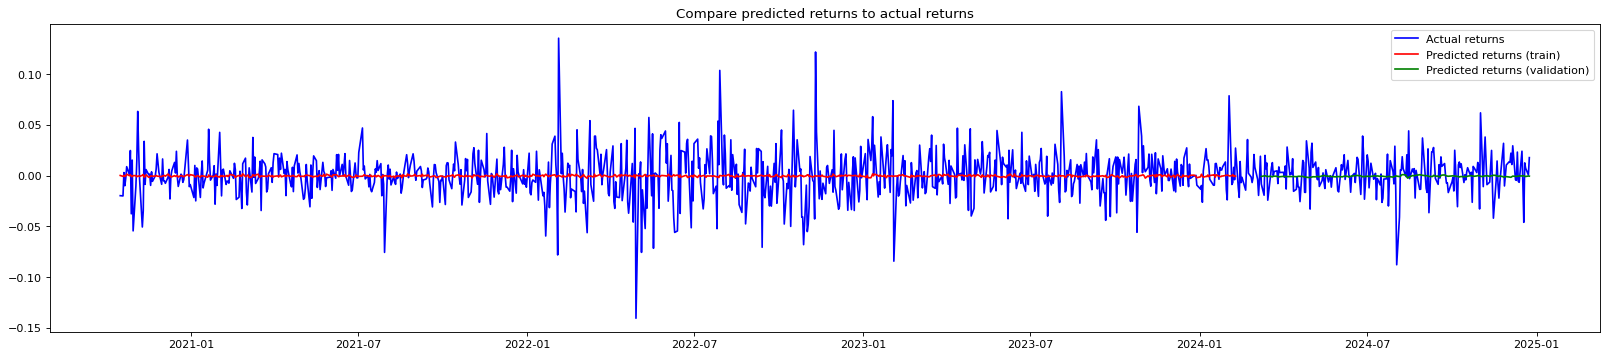

In [21]:
print(f"""
Model: epochs {max_iters}, dropout {dropout}, is_lstm {is_lstm},{f' hidden_size {n_hidden}, num_layers {n_layer},' if is_lstm else ''} lr {learning_rate}, scheduler_step_size {scheduler_step_size}, scheduler_gamma {scheduler_gamma}
Performance: train_mse {train_mse}, val_mse {val_mse}, f1_train {f1_train}, f1_val {f1_val}
Baseline: mse {baseline_mse}, f1 {baseline_f1}
Comp to baseline: train_mse {round((((train_mse - baseline_mse) / baseline_mse) * 100), 2)}%, val_mse {round((((val_mse - baseline_mse) / baseline_mse) * 100), 2)}%, f1_train {round((((f1_train - baseline_f1) / baseline_f1)*100), 2)}%, f1_val {round((((f1_val - baseline_f1) / baseline_f1)*100), 2)}%
""")



from matplotlib import pyplot as plt

dates = data.index


fig = plt.figure(figsize=(25, 5), dpi=80)
fig.patch.set_facecolor((1.0, 1.0, 1.0))
plt.plot(dates, data["1D Return"], label="Actual returns", color="blue")
plt.plot(dates, to_plot_data_y_train_pred, label="Predicted returns (train)", color="red")
plt.plot(dates, to_plot_data_y_val_pred, label="Predicted returns (validation)", color="green")
plt.title("Compare predicted returns to actual returns")
# plt.grid(b=None, which='major', axis='y', linestyle='--')
plt.legend()
plt.show()